In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import nltk
import re
from collections import Counter
from nltk.tokenize import word_tokenize
from nltk.stem.wordnet import WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet
from sklearn.feature_extraction.text import CountVectorizer
from nltk.sentiment.vader import SentimentIntensityAnalyzer
nltk.download('vader_lexicon')

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from imblearn.under_sampling import RandomUnderSampler

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.model_selection import GridSearchCV
from sklearn.svm import LinearSVC, LinearSVR
from sklearn.model_selection import cross_val_score
from sklearn.metrics import (f1_score, root_mean_squared_error, r2_score, confusion_matrix, ConfusionMatrixDisplay)
import shap
import warnings

pd.set_option('display.max_columns',None)
pd.set_option('display.max_colwidth', None)

def display_():
    plt.tight_layout()
    plt.show()

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\panda\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


In [2]:
DATA_DIR = Path("data")
DF_PATH = DATA_DIR / "02_cleaned_reviews_df.parquet"

df = pd.read_parquet(DF_PATH)

# Model Preprocessing
1) Vectorize unigram + bigrams
2) Feature scaling
3) Label encoding for Binary Classification (1-2 = Negative (0); 8-10 = Positive (1))
4) Train/Test Splits


In [3]:
engineered_cols = ['char_count', 'caps_count', 'caps_pct', 'sentiment']

# Vectorize ngrams + scale engineered features
preprocessor = ColumnTransformer([
    ('BOW', CountVectorizer(ngram_range=(1,2), min_df=5), 'reviews_cleaned'),
    ('Engineered', StandardScaler(), engineered_cols)
])
preprocessor_BC = ColumnTransformer([
    ('BOW', CountVectorizer(ngram_range=(1,2), min_df=5), 'reviews_cleaned'),
    ('Engineered', MinMaxScaler(clip=True), engineered_cols) # Uses minmax instead of z-scaling for positive value transformation
])

# Regression
train, test = train_test_split(df, test_size=0.2, stratify=df['rating'], random_state=0)
X_train, y_train= train[engineered_cols + ['reviews_cleaned']], train['rating']
X_test, y_test = test[engineered_cols + ['reviews_cleaned']], test['rating']

# Binary Classification
df_BC = df[~df['rating'].between(3,7)].copy()
df_BC['label'] = (df_BC['rating'] >= 8).astype(int)
train_BC, test_BC = train_test_split(df_BC, test_size=0.2, stratify=df_BC['rating'], random_state=0)
X_train_BC, y_train_BC= train_BC[engineered_cols + ['reviews_cleaned']], train_BC['label']
X_test_BC, y_test_BC = test_BC[engineered_cols + ['reviews_cleaned']], test_BC['label']


## Binary Classification Model
Models tested:
- Baseline: Logistic Regression
- Naive Bayes (ComplementNB)
- SVM (Linear SVC)

Evaluation Metric: F1 score (balances false positive & false negative rate)


Model F1 Score: 
Baseline: 0.9501
Linear SVC: 0.9532  {'model__C': 0.03, 'model__loss': 'squared_hinge'}
ComplementNB: 0.9147  {'model__alpha': 0.1, 'model__norm': False}

Selected Model: LinearSVC
Train F1: 0.9997
Test F1: 0.9530


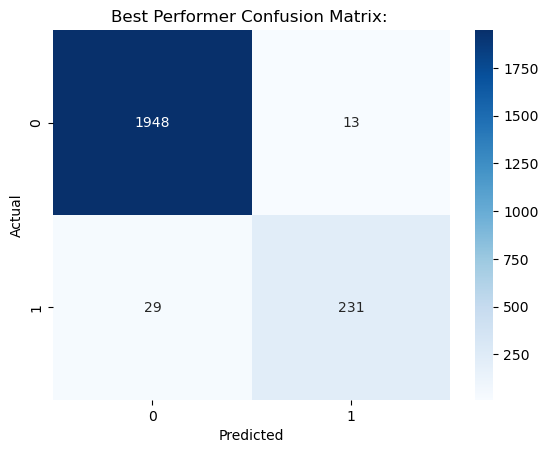

In [64]:
logreg = Pipeline([('preprocessor', clone(preprocessor_BC)), ('model', LogisticRegression(class_weight='balanced'))])
nb = Pipeline([('preprocessor', clone(preprocessor_BC)), ('model', ComplementNB())])
svc = Pipeline([('preprocessor', clone(preprocessor_BC)), ('model', LinearSVC(class_weight='balanced', max_iter=10000))])

# Model Performance Output
print("Model F1 Score: ")
scores = cross_val_score(logreg, X_train_BC, y_train_BC, cv=5, scoring='f1_macro', n_jobs=-1)
print(f"Baseline: {scores.mean():.4f}")

grids = {
    'Linear SVC':   (svc, {'model__C': [0.01, 0.03, 0.1, 0.3, 1], 'model__loss': ['hinge', 'squared_hinge']}),
    'ComplementNB': (nb,  {'model__alpha': [0.01, 0.1, 0.5, 1, 2], 'model__norm': [False, True]}),
}

tuned = {}
for name, (model, grid) in grids.items():
    gs = GridSearchCV(model, grid, cv=5, scoring='f1_macro', n_jobs=-1).fit(X_train_BC, y_train_BC)
    tuned[name] = gs
    print(f"{name}: {gs.best_score_:.4f}  {gs.best_params_}")

best_performer_BC = tuned[max(tuned, key=lambda model: tuned[model].best_score_)].best_estimator_
print(f"\nSelected Model: {type(best_performer_BC.named_steps['model']).__name__}")

print(f"Train F1: {f1_score(y_train_BC, best_performer_BC.predict(X_train_BC), average='macro'):.4f}")
print(f"Test F1: {f1_score(y_test_BC, best_performer_BC.predict(X_test_BC), average='macro'):.4f}")

cm = confusion_matrix(y_test_BC, best_performer_BC.predict(X_test_BC))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues")
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Best Performer Confusion Matrix: ')
plt.show()

## Regression Model
Models Tested:
- Baseline: Linear Regression
- Ridge Regression
- SVM (LinearSVR)

Evaluation Metric: Root Mean Squared Error

Model RMSE: 
Baseline: 2.2777
Ridge: 1.6960  {'model__alpha': 100}
SVM: 1.7184  {'model__C': 0.01, 'model__epsilon': 1}

Selected Model: Ridge
Train RMSE: 1.1202
Test RMSE: 1.6100


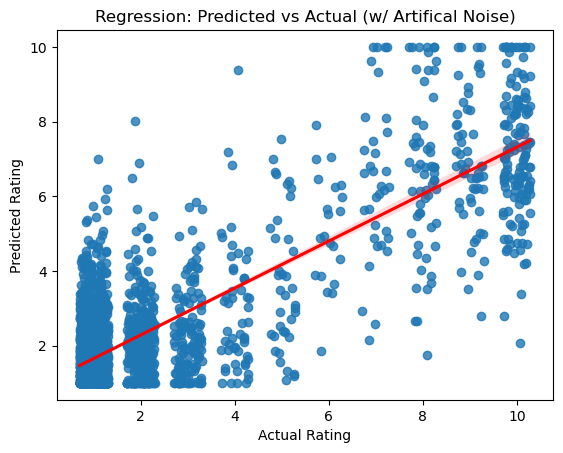

In [ ]:
linReg = Pipeline([('preprocessor', clone(preprocessor)), ('model', LinearRegression())])
ridgeReg = Pipeline([('preprocessor', clone(preprocessor)), ('model', Ridge())])
svr = Pipeline([('preprocessor', clone(preprocessor)), ('model', LinearSVR(max_iter=10000))])

print("Model RMSE: ")
scores = cross_val_score(linReg, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)
print(f"Baseline: {-scores.mean():.4f}")

grids = {
    'Ridge': (ridgeReg, {'model__alpha': [0.1, 1, 10, 100, 1000]}),
    'SVM': (svr, {'model__C': [0.01, 0.03, 0.1, 0.3, 1], 'model__epsilon': [0, 0.5, 1]}),
}

tuned_reg = {}
for name, (model, grid) in grids.items():
    gs = GridSearchCV(model, grid, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1).fit(X_train, y_train)
    tuned_reg[name] = gs
    print(f"{name}: {-gs.best_score_:.4f}  {gs.best_params_}")

best_performer_reg = tuned_reg[max(tuned_reg, key=lambda model: tuned_reg[model].best_score_)].best_estimator_
print(f"\nSelected Model: {type(best_performer_reg.named_steps['model']).__name__}")

print(f"Train RMSE: {root_mean_squared_error(y_train, best_performer_reg.predict(X_train)):.4f}")
print(f"Test RMSE: {root_mean_squared_error(y_test, best_performer_reg.predict(X_test)):.4f}")

jitter = np.random.uniform(-0.3, 0.3, size=len(y_test))
sns.regplot(x=y_test + jitter, y= np.clip(best_performer_reg.predict(X_test), 1, 10), line_kws={'color': 'red'})
plt.xlabel('Actual Rating')
plt.ylabel('Predicted Rating')
plt.title('Regression: Predicted vs Actual (w/ Artifical Noise)')
plt.show()



## Model Interpretation

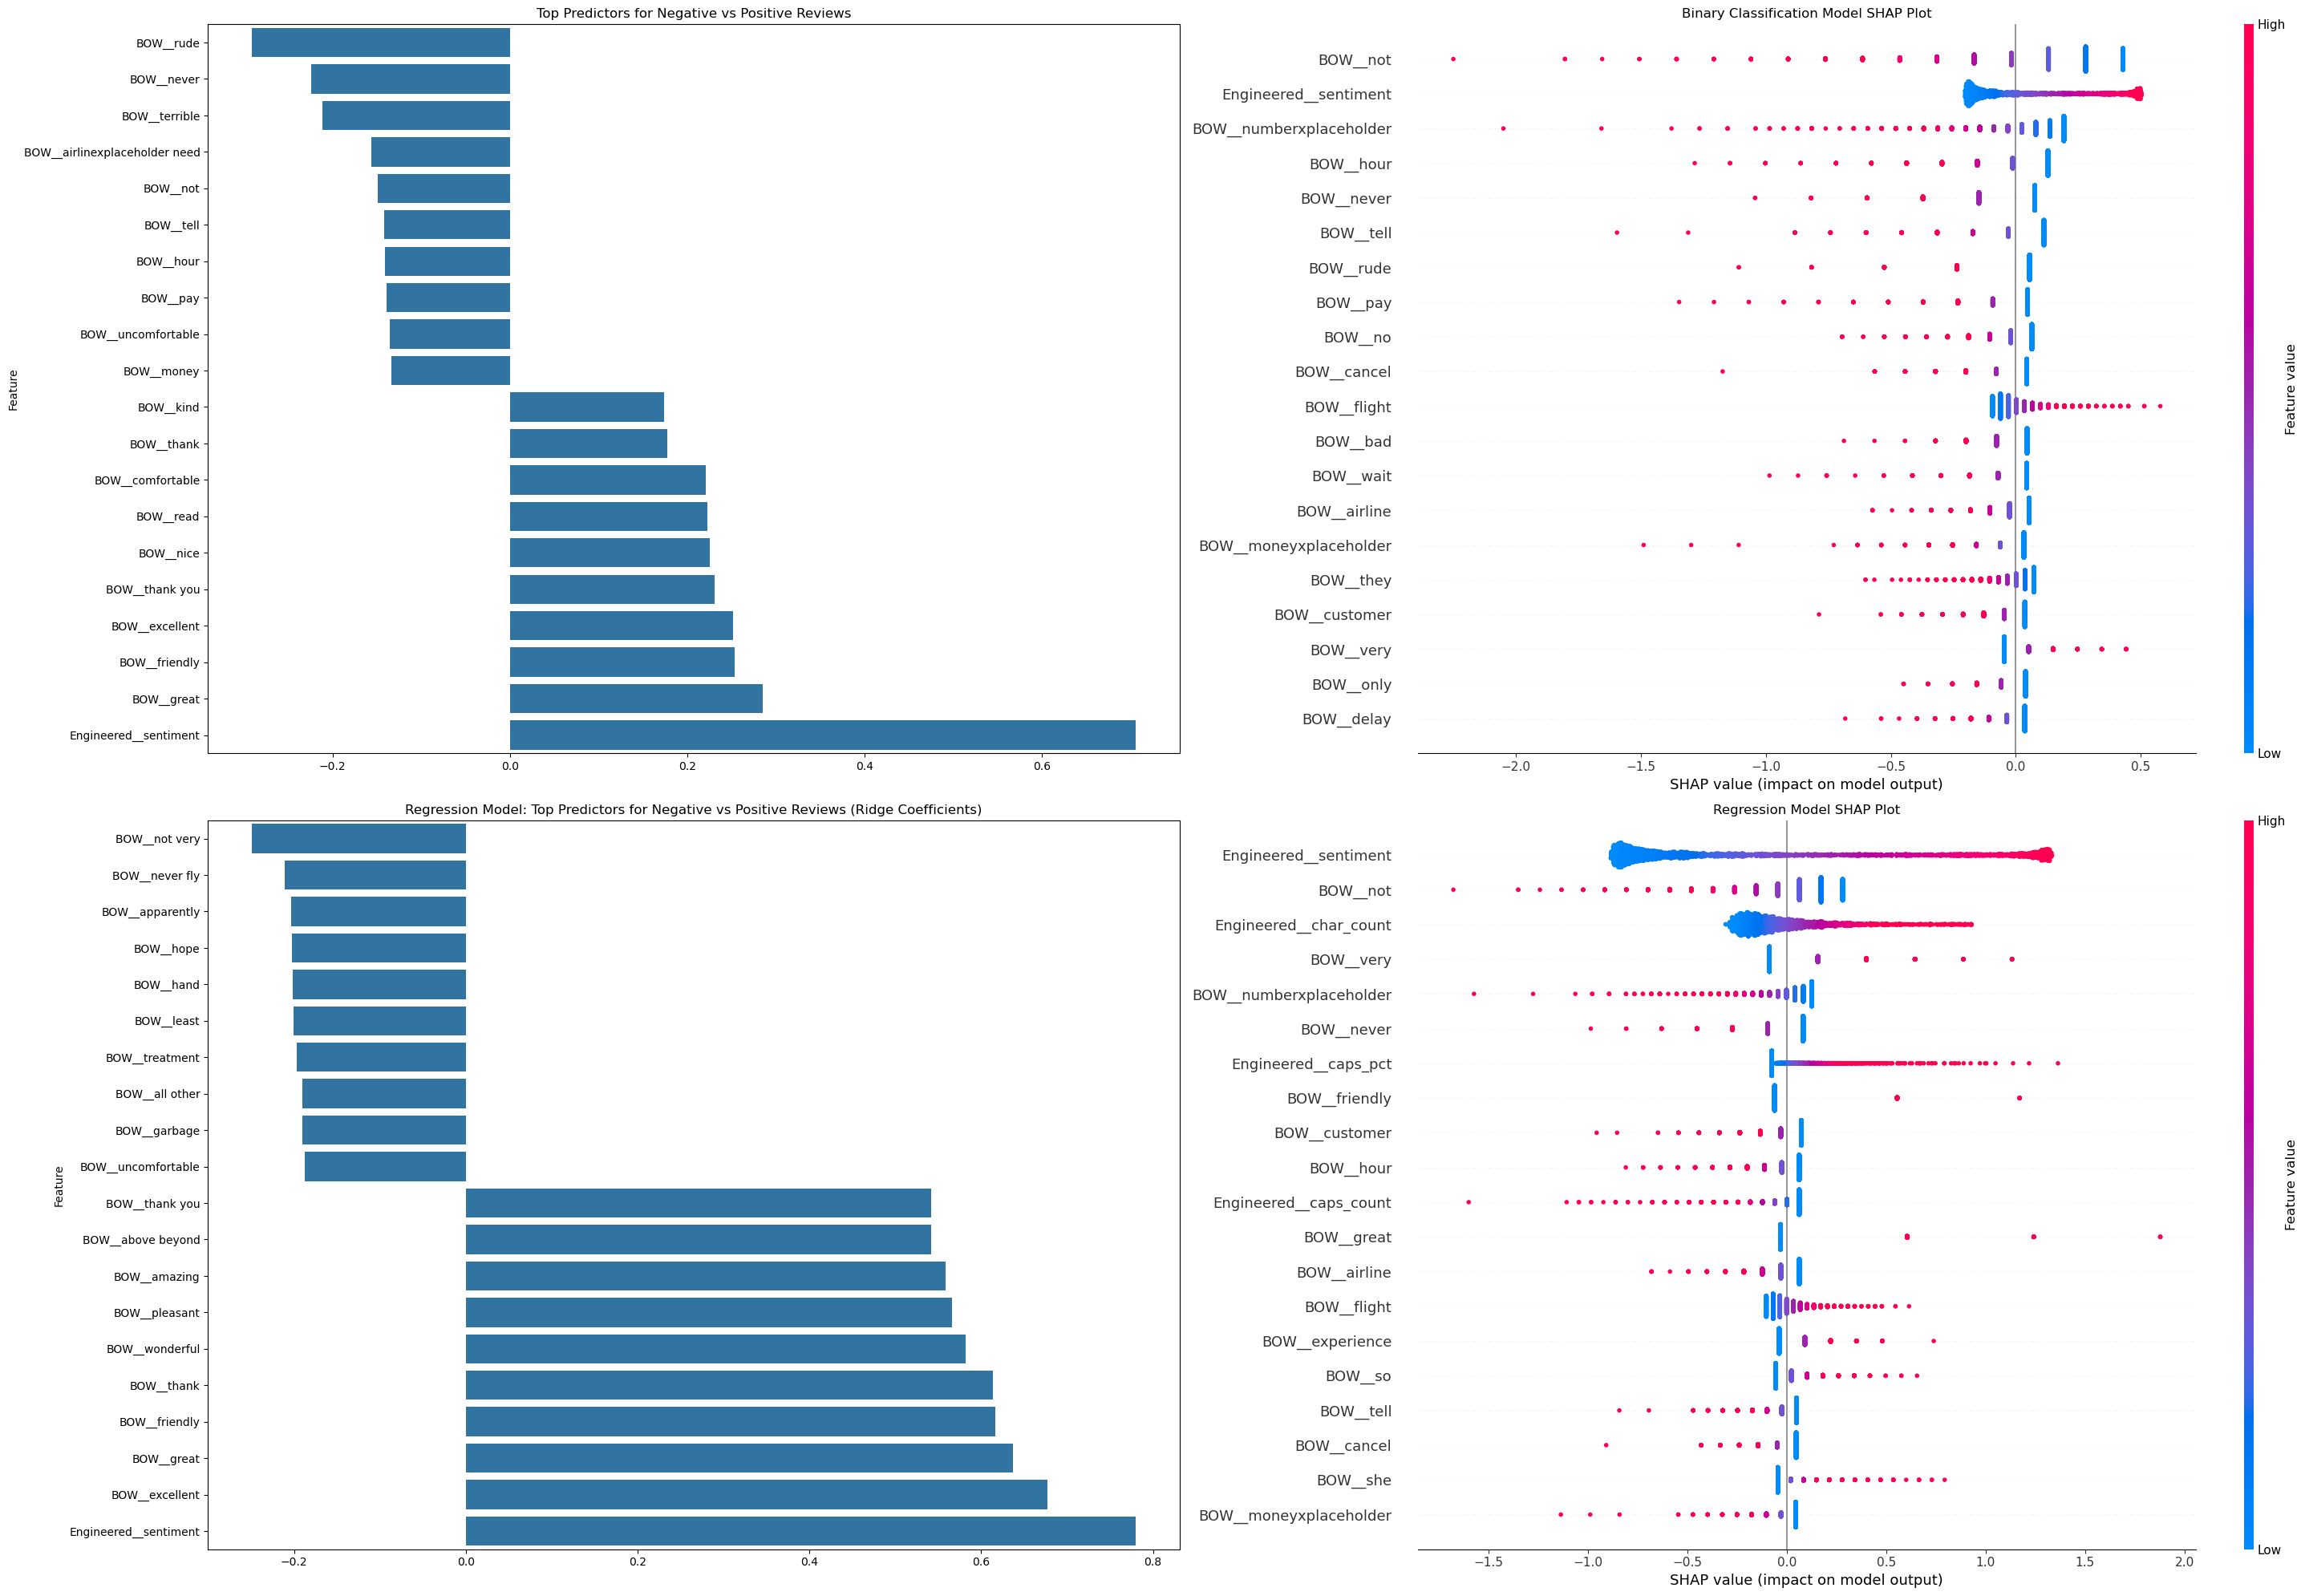

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(30, 20))

# binary classification coefficients
names = best_performer_BC.named_steps['preprocessor'].get_feature_names_out()
coefs = best_performer_BC.named_steps['model'].coef_
coef = pd.Series(coefs.ravel(), index=names).sort_values()
top_predictors = pd.concat([coef.head(10), coef.tail(10)])
sns.barplot(x=top_predictors.values, y=top_predictors.index, ax=axes[0, 0])
axes[0, 0].set_title('Binary Classification Model: Top Predictors for Negative vs Positive Reviews')
axes[0, 0].set_ylabel("Feature")

# binary classification SHAP
shap_features_BC = best_performer_BC.named_steps['preprocessor'].get_feature_names_out()
X_background_BC = best_performer_BC.named_steps['preprocessor'].transform(X_train_BC)
X_transformed_BC = best_performer_BC.named_steps['preprocessor'].transform(X_test_BC)
model_BC = (best_performer_BC.named_steps['model'].coef_.ravel(), best_performer_BC.named_steps['model'].intercept_)
shap_values_BC = shap.LinearExplainer(model_BC, X_background_BC).shap_values(X_transformed_BC)
plt.sca(axes[0, 1])
shap.summary_plot(shap_values_BC, X_transformed_BC.toarray(), feature_names=shap_features_BC, plot_size=None, show=False)
axes[0, 1].set_title("Binary Classification Model SHAP Plot")

# regression coefficients
reg_names = best_performer_reg.named_steps['preprocessor'].get_feature_names_out()
reg_coefs = pd.Series(best_performer_reg.named_steps['model'].coef_, index=reg_names).sort_values()
reg_top = pd.concat([reg_coefs.head(10), reg_coefs.tail(10)])
sns.barplot(x=reg_top.values, y=reg_top.index, ax=axes[1, 0])
axes[1, 0].set_title('Regression Model: Top Predictors for Negative vs Positive Reviews (Ridge Coefficients)')
axes[1, 0].set_ylabel("Feature")

# regression SHAP
X_background_reg = best_performer_reg.named_steps['preprocessor'].transform(X_train)
X_transformed_reg = best_performer_reg.named_steps['preprocessor'].transform(X_test)
shap_values_reg = shap.LinearExplainer(best_performer_reg.named_steps['model'], X_background_reg).shap_values(X_transformed_reg)
plt.sca(axes[1, 1])
shap.summary_plot(shap_values_reg, X_transformed_reg.toarray(), feature_names=reg_names, plot_size=None, show=False)
axes[1, 1].set_title("Regression Model SHAP Plot")

plt.tight_layout()
plt.show()

### Key Insights:
- Employee service and flight comfort are themes strongly reflected across both positive and negative reviews ("attitude", "treatment", "friendly", "kind", "uncomfortable/comfortable")
- Negative reviews often concern delays/disruptions or pricing/monetary demands ("pay", "money", [moneyxplaceholder])
- Higher ratings tend to have longer reviews than lower ratings
- Presence of bigram "never fly" suggests that negative experiences lead to a suggested permanent loss of a customer
- Presence of "all other" as a top predictor for negative reviews may suggest that customers notice airline-specific differences or issues. 

---------